# IS 4487 Assignment 11: Predicting Airbnb Prices with Regression

In this assignment, you will:
- Load the Airbnb dataset you cleaned and transformed in Assignment 7
- Build a linear regression model to predict listing price
- Interpret which features most affect price
- Try to improve your model using only the most impactful predictors
- Practice explaining your findings to a business audience like a host, pricing strategist, or city partner

## Why This Matters

Pricing is one of the most important levers for hosts and Airbnb’s business teams. Understanding what drives price — and being able to predict it accurately — helps improve search results, revenue management, and guest satisfaction.

This assignment gives you hands-on practice turning a cleaned dataset into a predictive model. You’ll focus not just on code, but on what the results mean and how you’d communicate them to stakeholders.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_11_regression.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Original Source: Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


## 1. Load Your Transformed Airbnb Dataset

**Business framing:**  
Before building any models, we must start with clean, prepared data. In Assignment 7, you exported a cleaned version of your Airbnb dataset. You’ll now import that file for analysis.

### Do the following:
- Import your CSV file called `cleaned_airbnb_data_7.csv`.   (Note: If you had significant errors with assignment 7, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)
- Use `pandas` to load and preview the dataset


In [2]:

df = pd.read_csv("airbnb_listings.csv")
print("Dataset Shape:", df.shape)
display(df.head())
print(df.columns.tolist())
df.info()

Dataset Shape: (459, 77)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,host_url,host_name,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2992450,https://www.airbnb.com/rooms/2992450,20250804133828,2025-08-04,city scrape,Luxury 2 bedroom apartment,The apartment is located in a quiet neighborho...,NaN,https://www.airbnb.com/users/show/4621559,Kenneth,...,4.56,3.22,3.67,NaN,0,1,1,0,0,0.07
1,3820211,https://www.airbnb.com/rooms/3820211,20250804133828,2025-08-04,city scrape,Funky Urban Gem: Prime Central Location - Park...,Step into the charming and comfy 1BR/1BA apart...,Overview<br /><br />The lovely apartment is lo...,https://www.airbnb.com/users/show/19648678,Terra,...,4.81,4.81,4.77,NaN,0,4,4,0,0,2.32
2,5651579,https://www.airbnb.com/rooms/5651579,20250804133828,2025-08-04,city scrape,Large studio apt by Capital Center & ESP@,"Spacious studio with hardwood floors, fully eq...",The neighborhood is very eclectic. We have a v...,https://www.airbnb.com/users/show/29288920,Gregg,...,4.88,4.76,4.64,NaN,0,2,1,1,0,2.97
3,6623339,https://www.airbnb.com/rooms/6623339,20250804133828,2025-08-04,city scrape,Bright & Cozy City Stay · Top Location + Parking!,Step into the charming and comfy 1BR/1BA apart...,Overview<br /><br />The lovely apartment is lo...,https://www.airbnb.com/users/show/19648678,Terra,...,4.70,4.80,4.72,NaN,0,4,4,0,0,2.68
4,9005989,https://www.airbnb.com/rooms/9005989,20250804133828,2025-08-04,city scrape,"Studio in The heart of Center SQ, in Albany NY",(21 years of age or older ONLY) NON- SMOKING.....,"There are many shops, restaurants, bars, museu...",https://www.airbnb.com/users/show/17766924,Sugey,...,4.93,4.87,4.77,NaN,0,1,1,0,0,5.67


['id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name', 'description', 'neighborhood_overview', 'host_url', 'host_name', 'host_since', 'host_location', 'host_about', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_is_superhost', 'host_thumbnail_url', 'host_picture_url', 'host_neighbourhood', 'host_listings_count', 'host_total_listings_count', 'host_verifications', 'host_has_profile_pic', 'host_identity_verified', 'neighbourhood', 'neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'latitude', 'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'calendar_updated', 'has_availability', 'availability_30', 'availability_60', 'availability_90', 'availability_365', 'calendar_last_s

### Reflection:
1. What business information does the dataset include?
2. How many rows and columns are present?

### ✍️ Your Response: 🔧
1.
This dataset includes information about different properties on airbnb. It has characteristics like availability, host info, location, reviews and many more characteristics/ info.
2.
It has 459 rows and 77 columns.

## 2. Drop Columns Not Useful for Modeling

**Business framing:**  
Some columns — like post IDs or text — may not help us predict price and could add noise or bias.

### Do the following:
- Drop columns like `post_id`, `title`, `descr`, `details`, and `address` if they’re still in your dataset

In [4]:

df_model = df.drop(columns=[
    'id', 'listing_url', 'scrape_id',
    'name', 'description', 'neighborhood_overview',
    'host_url', 'host_name', 'host_about',
    'host_thumbnail_url', 'host_picture_url',
    'amenities', 'license',
     'estimated_revenue_l365d'
])
df_model = df_model.select_dtypes(include=['number'])
print("Dataset Shape:", df_model.shape)
print(df_model.head())

Dataset Shape: (459, 40)
   host_listings_count  host_total_listings_count  latitude  longitude  \
0                    1                          5  42.65789  -73.75370   
1                    4                          6  42.65222  -73.76724   
2                    2                          2  42.64615  -73.75966   
3                    4                          6  42.65222  -73.76724   
4                    1                          1  42.65559  -73.76506   

   accommodates  bathrooms  bedrooms  beds  price  minimum_nights  ...  \
0             4        1.0       2.0   2.0   70.0              28  ...   
1             2        1.0       1.0   1.0  104.0               2  ...   
2             2        1.0       0.0   1.0   75.0               2  ...   
3             2        1.0       1.0   1.0  101.0               2  ...   
4             4        1.0       1.0   2.0  110.0               1  ...   

   review_scores_checkin  review_scores_communication  review_scores_location  \
0   

### Reflection:
1. What columns did you drop, and why?
2. What risks might occur if you included them in your model?

### ✍️ Your Response: 🔧
1.
I removed columsn that are basically unique Identifiers like ID's and adresses and then I also tried to only keep numeric columns.
2.
I tried to keep numeric columns because the model couldn't handle string outputs and then I also dropped unique identifiers because they are no help to the model.

## 3. Explore Relationships Between Numeric Features

**Business framing:**  
Understanding how features relate to each other — and to the target — helps guide feature selection and modeling.

### Do the following:
- Generate a correlation matrix
- Identify which variables are strongly related to `price`

Correlations with Price:
price                                           1.000000
accommodates                                    0.579588
beds                                            0.547032
bedrooms                                        0.499286
bathrooms                                       0.468030
maximum_maximum_nights                          0.122872
minimum_maximum_nights                          0.112166
maximum_nights_avg_ntm                          0.111271
availability_30                                 0.108409
availability_60                                 0.060509
availability_90                                 0.040997
calculated_host_listings_count_entire_homes     0.033206
availability_eoy                                0.032537
review_scores_value                             0.018269
maximum_nights                                  0.017992
calculated_host_listings_count                  0.015773
review_scores_cleanliness                      -0.000918
host_t

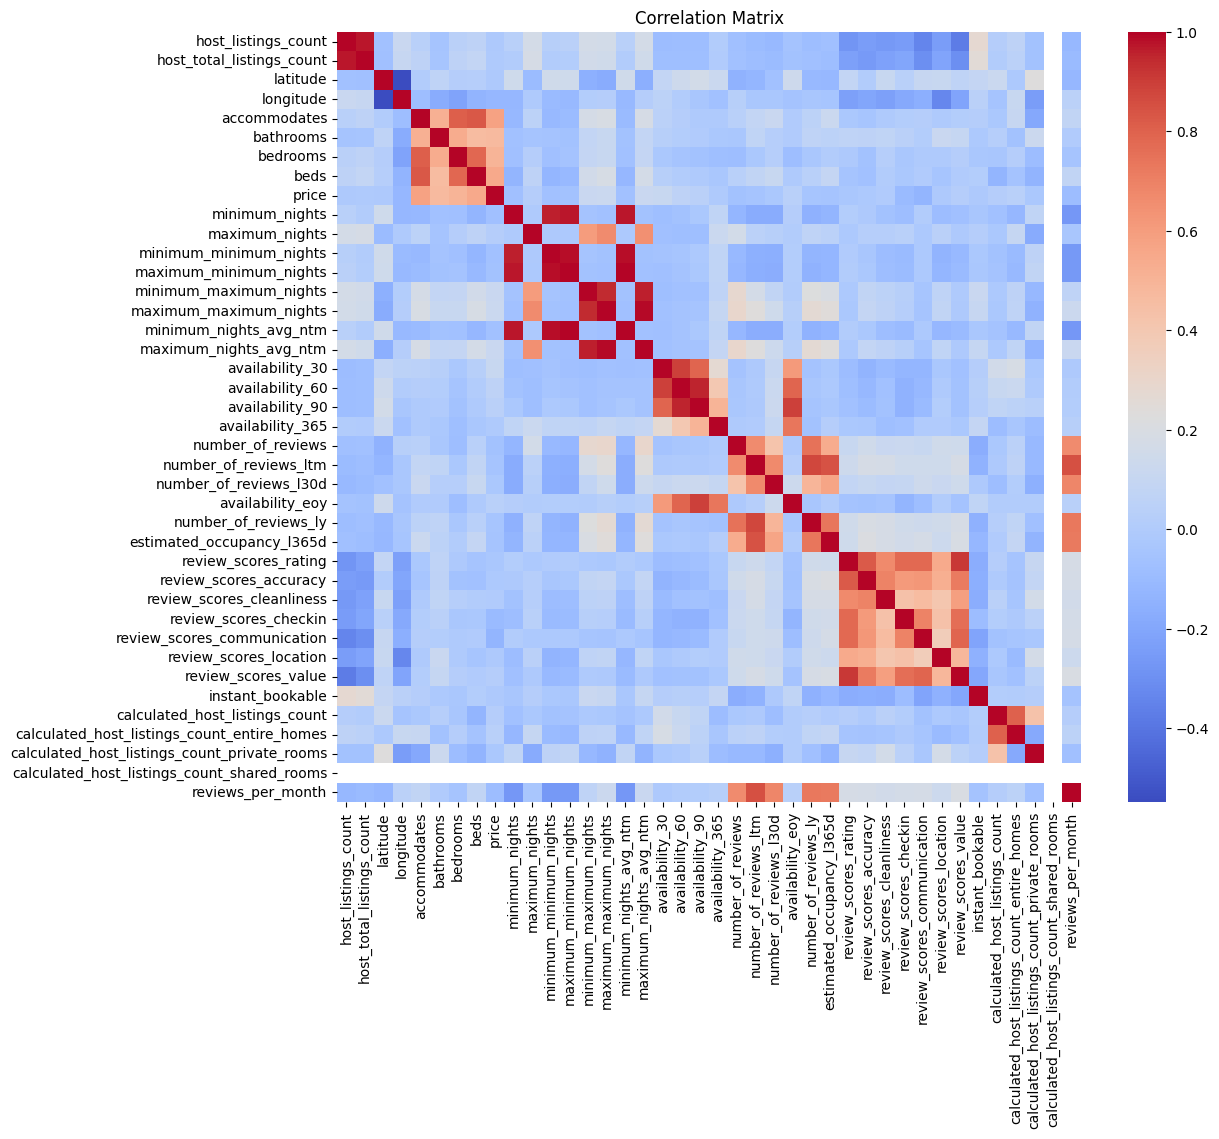

In [5]:

correlation_matrix = df_model.corr()
price_correlations = correlation_matrix['price'].sort_values(ascending=False)

print("Correlations with Price:")
print(price_correlations)
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

### Reflection:
1. Which variables had the strongest positive or negative correlation with price?
2. Which variables might be useful predictors?

### ✍️ Your Response: 🔧
1.
Accommodates, Beds, Bathrooms, and Bedrooms had the strongest correlation with price.
2.
Basically varibles that have to do with the size of the property and how many people it can accomodate seems to be the best variables.

## 4. Define Features and Target Variable

**Business framing:**  
To build a regression model, you need to define what you’re predicting (target) and what you’re using to make that prediction (features).

### Do the following:
- Set `price` as your target variable
- Remove `price` from your predictors

In [6]:

y = df_model['price']
X = df_model.drop(columns=['price'])
X = X.fillna(X.median())
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("\nFeatures:")
print(X.columns.tolist())

Features Shape: (459, 39)
Target Shape: (459,)

Features:
['host_listings_count', 'host_total_listings_count', 'latitude', 'longitude', 'accommodates', 'bathrooms', 'bedrooms', 'beds', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'availability_30', 'availability_60', 'availability_90', 'availability_365', 'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'availability_eoy', 'number_of_reviews_ly', 'estimated_occupancy_l365d', 'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 'review_scores_value', 'instant_bookable', 'calculated_host_listings_count', 'calculated_host_listings_count_entire_homes', 'calculated_host_listings_count_private_rooms', 'calculated_host_listings_count_shared_rooms', 'reviews_per_month']


### Reflection:
1. What features are you using?
2. Why is this a regression problem and not a classification problem?

### ✍️ Your Response: 🔧
1.
I am using features like guest capacity, bedrooms, bathrooms, and host info.
2.
This is a regression issue because we are trying to predict a numerical value.

## 5. Split Data into Training and Testing Sets

### Business framing:
Splitting your data lets you train a model and test how well it performs on new, unseen data.

### Do the following:
- Use `train_test_split()` to split into 80% training, 20% testing



In [7]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Training Set:", X_train.shape)
print("Testing Set:", X_test.shape)

Training Set: (367, 39)
Testing Set: (92, 39)


## 6. Fit a Linear Regression Model

### Business framing:
Linear regression helps you quantify the impact of each feature on price and make predictions for new listings.

### Do the following:
- Fit a linear regression model to your training data
- Use it to predict prices for the test set



In [8]:

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
results = pd.DataFrame({
    'Actual Price': y_test,
    'Prediction Price': y_pred
})

display(results.head(10))

,Actual Price,Prediction Price
124,93.0,100.473533
30,54.0,96.885296
199,59.0,100.060819
438,59.0,89.333417
154,102.0,66.706781
225,95.0,88.346484
405,65.0,65.700272
296,95.0,44.266491
222,95.0,98.453925
75,118.0,81.866490


## 7. Evaluate Model Performance

### Business framing:  
A good model should make accurate predictions. We’ll use Mean Squared Error (MSE) and R² to evaluate how close our predictions were to the actual prices.

### Do the following:
- Print MSE and R² score for your model

In [11]:

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("Mean Squared Error:", mse)
print("R Squared Score:", r2)

Mean Squared Error: 8183.150031613127
R Squared Score: -0.4580226763500552


### Reflection:
1. What is your R² score? How well does your model explain price variation?
2. Is your MSE large or small? What could you do to improve it?

### ✍️ Your Response: 🔧
1.
My R squared score is negative .45 which basically means the model sucks.
2.
My MSE was alarge sow the predictions were not very accurate I wam going to try and remove less useful predictors.

## 8. Interpret Model Coefficients

### Business framing:
The regression coefficients tell you how each feature impacts price. This can help Airbnb guide hosts and partners.

### Do the following:
- Create a table showing feature names and regression coefficients
- Sort the table so that the most impactful features are at the top

In [10]:

coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})
coefficients['Absolute Coefficient'] = coefficients['Coefficient'].abs()

coefficients = coefficients.sort_values(
    by='Absolute Coefficient', ascending=False
)
display(coefficients)

,Feature,Coefficient,Absolute Coefficient
2,latitude,-1179.785818,1179.785818
3,longitude,-573.436472,573.436472
30,review_scores_communication,-133.954299,133.954299
32,review_scores_value,126.504520,126.504520
29,review_scores_checkin,-90.730982,90.730982
11,maximum_minimum_nights,-36.155302,36.155302
14,minimum_nights_avg_ntm,35.868806,35.868806
5,bathrooms,34.911578,34.911578
28,review_scores_cleanliness,-25.655869,25.655869
7,beds,21.431536,21.431536


### Reflection:
1. Which features increased price the most?
2. Were any surprisingly negative?
3. What business insight could you draw from this?

### ✍️ Your Response: 🔧
1.
The features that had a large positive coefficient was review scores, minimum nights average, bathrooms, and beds.

2.
Yes, check in ratings, and communication ratings were really negative.
3.
I would basically draw that location, guest ratings, and house size should be the main thigns whens etting prices.

## 9. Try to Improve the Linear Regression Model

### Business framing:
The first version of your model included all available features — but not all features are equally useful. Removing weak or noisy predictors can often improve performance and interpretation.

### Do the following:
1. Choose your top 3–5 features with the strongest absolute coefficients
2. Rebuild the regression model using just those features
3. Compare MSE and R² between the baseline and refined model

In [13]:

top_features = [ 'accommodates', 'beds', 'bedrooms', 'bathrooms', 'review_scores_value'
]

X_refined = X[top_features]

X_train_refined, X_test_refined, y_train_refined, y_test_refined = train_test_split(
    X_refined, y, test_size=0.2, random_state=42
)
refined_model = LinearRegression()
refined_model.fit(X_train_refined, y_train_refined)
y_pred_refined = refined_model.predict(X_test_refined)
mse_refined = mean_squared_error(y_test_refined, y_pred_refined)
r2_refined = r2_score(y_test_refined, y_pred_refined)

print("Original Model MSE:", mse)
print("Refined Model MSE:", mse_refined)

print("\nOriginal Model R Squared:", r2)
print("Refined Model R Squared:", r2_refined)

print("\nSelected Features:", top_features)

Original Model MSE: 8183.150031613127
Refined Model MSE: 3342.923950420536

Original Model R Squared: -0.4580226763500552
Refined Model R Squared: 0.4043786431634032

Selected Features: ['accommodates', 'beds', 'bedrooms', 'bathrooms', 'review_scores_value']


### Reflection:
1. What features did you keep in the refined model, and why?
2. Did model performance improve? Why or why not?
3. Which model would you recommend to stakeholders?
4. How does this relate to your customized learning outcome you created in canvas?

### ✍️ Your Response: 🔧
1.
I kept accommodates, beds, bedrooms, bathrooms, and revview scores value as they had strong correlations with price and also from a business perspective made sense why they would increase the value


2.
Yes the models' R Squared increasesed significantly and also had a decreased MSe as well showing that getting rid of bad predictors helped.

3.

I would reccomend the revised one as it was more simple and way more successful.
4.

This assignment helped me practice using a regression analysis with real world data to indentify the 5 most important variables and how to commuincate them to shareholders.

## 10. Reflect and Recommend

### Business framing:  
Ultimately, the value of your model comes from how well it can guide business decisions. Use your results to make real-world recommendations.

### Reflection:
1. What business question did your model help answer?
2. What would you recommend to Airbnb or its hosts?
3. What could you do next to improve this model or make it more useful?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1.
Which listing characteristics are most useful for predicting prices
2.
I would reccomend that they consider bedrooms, bathrooms, reviews, and overall guest cpacity when setting prices and also trying to increase those things so that they can increase prices.
3.
I could sift through the characteristics more and add additional info instead of just using the 5 best ones I think the main info I missed out on was location which makes a big difference so that is where I would start.

4.

This related to my custome learning outcomes because I talked a lot about relating to real world situations which is what was cool about this assignment as we were using real world data from a real company.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_11_regression.ipynb"